# Exploratory Data Analysis & Data Cleaning - UNSW-NB15 Dataset

The **UNSW-NB15** dataset is a benchmark network intrusion detection dataset generated by the Cyber Range Lab of the Australian Centre for Cyber Security (ACCS). It captures a realistic mixture of modern normal network traffic and synthetic contemporary cyber attack activities.

---

### Structure of this Notebook:
1. **Data Ingestion**: Robust loading of training set.
2. **Dataset Overview & Quality Assessment**: Inspect schema, null values, placeholders, and duplicates.
3. **Target Variable Exploration**: Binary (`label`) and multiclass (`attack_cat`) distributions.
4. **Categorical Feature Analysis**: Protocol (`proto`), service (`service`), and connection state (`state`).
5. **Numerical Feature Distribution & Network Metrics**: Volume, rates, duration, TTL, and TCP windows.
6. **Connection Count Features (`ct_*`)**: Frequency-based indicators across attack vs. normal traffic.
7. **Correlation & Multicollinearity**: Identifying redundant features (|r| > 0.85).
8. **Feature Importance Screening**: Random Forest Gini importance for traffic discrimination.
9. **EDA Summary & Key Findings**: Synthesis of analytical takeaways.
10. **Data Cleaning & Transformation Pipeline**:
    - Whitespace stripping and string standardization
    - Handling placeholder values (`'-'` in `service`)
    - Correcting logical flag anomalies (`is_ftp_login` values > 1)
    - Deduplication analysis and handling
    - Skewness correction via `log1p` transformations
    - Feature pruning of identifiers (`id`)
    - Pipeline application to both Training and Testing sets
    - Export of cleaned datasets (`UNSW_NB15_training-set_cleaned.csv` and `UNSW_NB15_testing-set_cleaned.csv`)


In [1]:
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

# Configuration & visual styling
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.4f' % x)


## 1. Data Ingestion
Load the UNSW-NB15 training dataset CSV file. We establish robust path resolution to seamlessly support execution from both the notebook directory and workspace root.

In [2]:
candidate_paths = [
    Path('../../datasets/UNSW-NB15 dataset/CSV Files/Training and Testing Sets/UNSW_NB15_training-set.csv'),
    Path('datasets/UNSW-NB15 dataset/CSV Files/Training and Testing Sets/UNSW_NB15_training-set.csv'),
    Path(r'd:/Swinburne Courses/Project A/datasets/UNSW-NB15 dataset/CSV Files/Training and Testing Sets/UNSW_NB15_training-set.csv')
]

data_path = next((p for p in candidate_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Could not locate UNSW_NB15_training-set.csv")

print(f"Loading dataset from: {data_path.resolve()}")
df = pd.read_csv(data_path)
print(f"Dataset successfully loaded. Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Loading dataset from: D:\Swinburne Courses\Project A\datasets\UNSW-NB15 dataset\CSV Files\Training and Testing Sets\UNSW_NB15_training-set.csv


Dataset successfully loaded. Shape: 175,341 rows x 45 columns


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.1215,tcp,-,FIN,6,4,258,172,74.0875,252,254,14158.9424,8495.3652,0,0,24.2956,8.3750,30.1775,11.8306,255,621772692,2202533631,255,0.0000,0.0000,0.0000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.6499,tcp,-,FIN,14,38,734,42014,78.4734,62,252,8395.1123,503571.3125,2,17,49.9150,15.4329,61.4269,1387.7783,255,1417884146,3077387971,255,0.0000,0.0000,0.0000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.6231,tcp,-,FIN,8,16,364,13186,14.1702,62,252,1572.2719,60929.2305,1,6,231.8756,102.7372,17179.5869,11420.9262,255,2116150707,2963114973,255,0.1119,0.0615,0.0504,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.6816,tcp,ftp,FIN,12,12,628,770,13.6771,62,252,2740.1790,3358.6221,1,3,152.8765,90.2357,259.0802,4991.7847,255,1107119177,1047442890,255,0.0000,0.0000,0.0000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.4495,tcp,-,FIN,10,6,534,268,33.3738,254,252,8561.4990,3987.0598,2,1,47.7503,75.6596,2415.8376,115.8070,255,2436137549,1977154190,255,0.1284,0.0711,0.0572,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


## 2. Dataset Overview & Data Quality Assessment
Examine data types, missing records, duplicates, and column categories.

In [3]:
print("--- Dataset Schema Info ---")
df.info()

print("\n--- Missing Values Inspection ---")
missing = df.isnull().sum()
missing_cols = missing[missing > 0]
if len(missing_cols) == 0:
    print("No null/NaN values detected across any columns.")
else:
    print(missing_cols)

feature_cols = [c for c in df.columns if c != 'id']
duplicates = df.duplicated(subset=feature_cols).sum()
print(f"\nNumber of duplicate records (ignoring 'id'): {duplicates:,} ({duplicates / len(df) * 100:.2f}%)")


--- Dataset Schema Info ---
<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  str    
 3   service            175341 non-null  str    
 4   state              175341 non-null  str    
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null


Number of duplicate records (ignoring 'id'): 67,601 (38.55%)


### Inspecting Special Placeholder Values
In network datasets, missing or unclassified attributes are often designated with placeholders such as `'-'` (e.g., in the `service` column when traffic doesn't map to a standard application layer port).

In [4]:
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    dash_count = (df[col] == '-').sum()
    if dash_count > 0:
        print(f"Column '{col}' has {dash_count:,} placeholder '-' entries ({dash_count / len(df) * 100:.2f}%)")


Column 'service' has 94,168 placeholder '-' entries (53.71%)


## 3. Target Variable Exploration
The dataset contains two target labels:
- **`label`**: Binary indicator (`0` = Normal traffic, `1` = Attack traffic).
- **`attack_cat`**: Multiclass category detailing the specific attack family (or `Normal`).

In [5]:
# Binary target distribution
binary_counts = df['label'].value_counts()
binary_pcts = df['label'].value_counts(normalize=True) * 100
binary_summary = pd.DataFrame({'Count': binary_counts, 'Percentage (%)': binary_pcts})
binary_summary.index = binary_summary.index.map({0: 'Normal (0)', 1: 'Attack (1)'})
print("Binary Target Distribution:")
display(binary_summary)

# Multi-class attack category distribution
cat_counts = df['attack_cat'].value_counts()
cat_pcts = df['attack_cat'].value_counts(normalize=True) * 100
cat_summary = pd.DataFrame({'Count': cat_counts, 'Percentage (%)': cat_pcts})
print("\nAttack Category Distribution:")
display(cat_summary)


Binary Target Distribution:


,Count,Percentage (%)
label,,
Attack (1),119341,68.0622
Normal (0),56000,31.9378



Attack Category Distribution:


,Count,Percentage (%)
attack_cat,,
Normal,56000,31.9378
Generic,40000,22.8127
Exploits,33393,19.0446
Fuzzers,18184,10.3706
DoS,12264,6.9944
Reconnaissance,10491,5.9832
Analysis,2000,1.1406
Backdoor,1746,0.9958
Shellcode,1133,0.6462


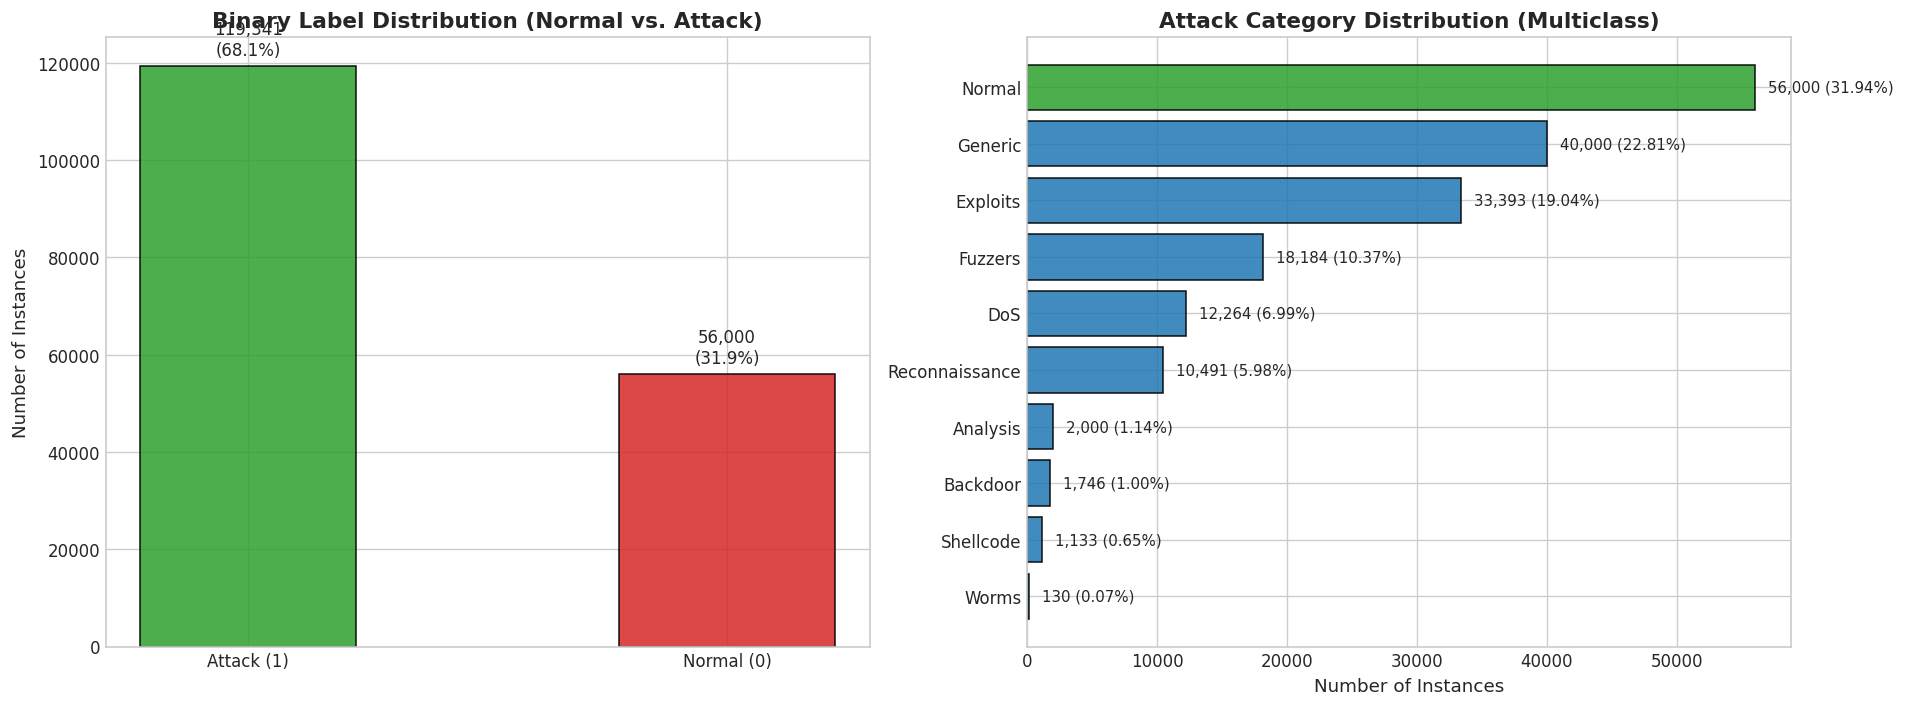

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = ['#2ca02c', '#d62728']
bars1 = axes[0].bar(binary_summary.index, binary_summary['Count'], color=colors, edgecolor='black', alpha=0.85, width=0.45)
axes[0].set_title('Binary Label Distribution (Normal vs. Attack)', fontweight='bold')
axes[0].set_ylabel('Number of Instances')
for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 1500, f'{yval:,}\n({yval/len(df)*100:.1f}%)', 
                 ha='center', va='bottom', fontsize=10)

cat_sorted = cat_summary.sort_values(by='Count', ascending=True)
palette = ['#2ca02c' if idx == 'Normal' else '#1f77b4' for idx in cat_sorted.index]
axes[1].barh(cat_sorted.index, cat_sorted['Count'], color=palette, edgecolor='black', alpha=0.85)
axes[1].set_title('Attack Category Distribution (Multiclass)', fontweight='bold')
axes[1].set_xlabel('Number of Instances')
for i, (count, pct) in enumerate(zip(cat_sorted['Count'], cat_sorted['Percentage (%)'])):
    axes[1].text(count + 1000, i, f'{count:,} ({pct:.2f}%)', va='center', fontsize=9)

plt.tight_layout()
plt.show()


> **Class Imbalance Insights:**
> - In this training set, Attack instances (119,341 / 68.06%) exceed Normal instances (56,000 / 31.94%).
> - Among attack categories, `Generic` (40,000), `Exploits` (33,393), and `Fuzzers` (18,184) constitute the majority.
> - Rare attacks like `Worms` (130 instances), `Shellcode` (1,133), and `Backdoor` (1,746) have extremely low representation, requiring stratified splits and class-weighting or anomaly detection methods during model training.


## 4. Categorical Feature Analysis
Examine the distributions of `proto` (transport/network protocol), `service` (application service), and `state` (connection state).

Unique Protocols: 133
Unique Services:  13
Unique States:    9


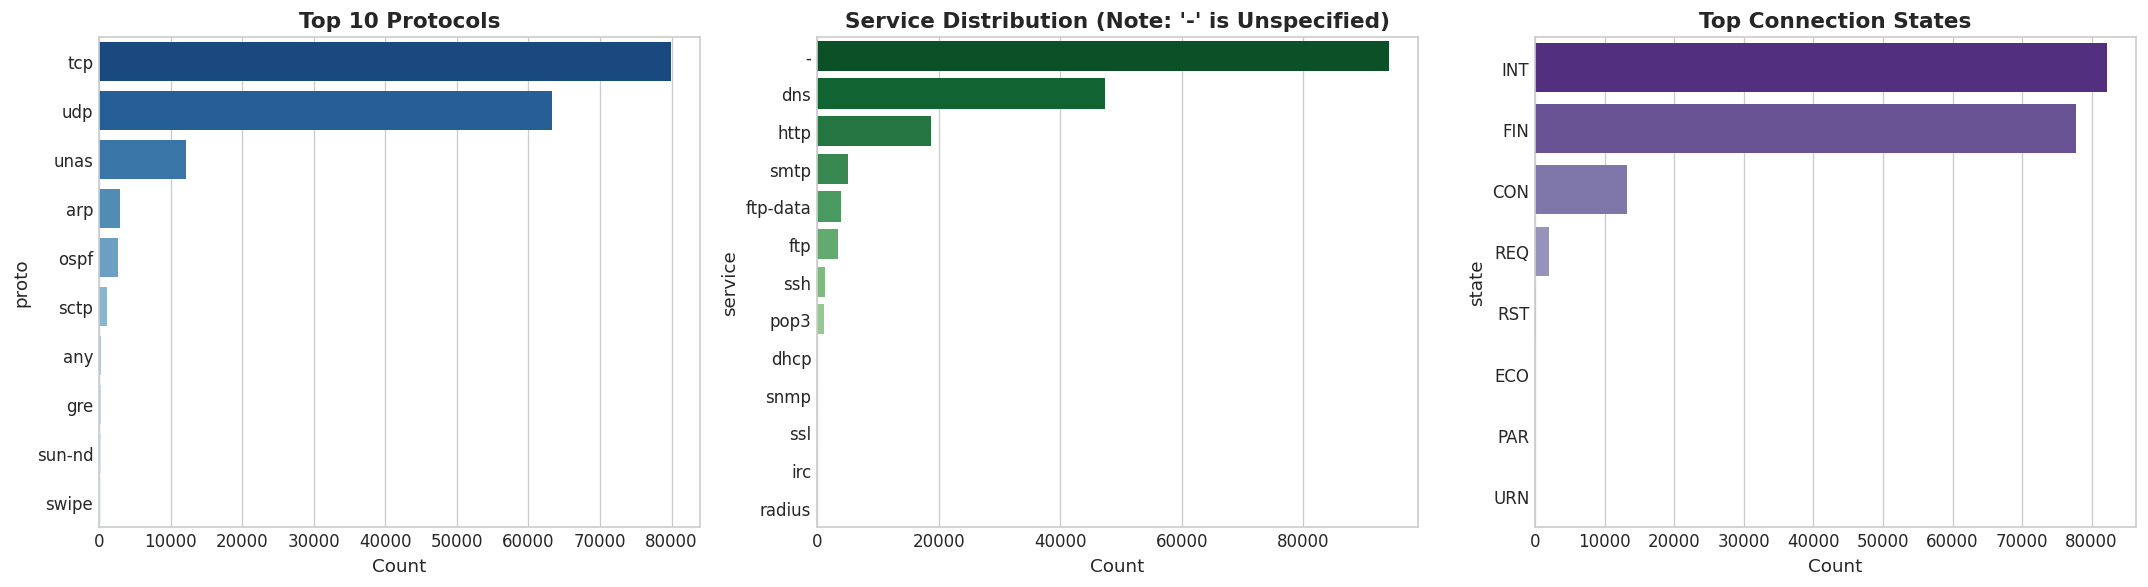

In [7]:
print(f"Unique Protocols: {df['proto'].nunique()}")
print(f"Unique Services:  {df['service'].nunique()}")
print(f"Unique States:    {df['state'].nunique()}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

top_proto = df['proto'].value_counts().head(10)
sns.barplot(x=top_proto.values, y=top_proto.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 10 Protocols', fontweight='bold')
axes[0].set_xlabel('Count')

service_counts = df['service'].value_counts()
sns.barplot(x=service_counts.values, y=service_counts.index, ax=axes[1], palette='Greens_r')
axes[1].set_title("Service Distribution (Note: '-' is Unspecified)", fontweight='bold')
axes[1].set_xlabel('Count')

top_state = df['state'].value_counts().head(8)
sns.barplot(x=top_state.values, y=top_state.index, ax=axes[2], palette='Purples_r')
axes[2].set_title('Top Connection States', fontweight='bold')
axes[2].set_xlabel('Count')

plt.tight_layout()
plt.show()


In [8]:
# Service vs Attack Label cross-tabulation
service_crosstab = pd.crosstab(df['service'], df['label'], normalize='index') * 100
service_crosstab.columns = ['Normal (%)', 'Attack (%)']
service_crosstab['Total Counts'] = df['service'].value_counts()
service_crosstab = service_crosstab.sort_values(by='Total Counts', ascending=False)
print("Service vs. Attack Label Breakdown:")
display(service_crosstab)

# State vs Attack Label cross-tabulation
state_crosstab = pd.crosstab(df['state'], df['label'], normalize='index') * 100
state_crosstab.columns = ['Normal (%)', 'Attack (%)']
state_crosstab['Total Counts'] = df['state'].value_counts()
state_crosstab = state_crosstab.sort_values(by='Total Counts', ascending=False).head(10)
print("\nTop Connection States vs. Attack Label Breakdown:")
display(state_crosstab)


Service vs. Attack Label Breakdown:


,Normal (%),Attack (%),Total Counts
service,,,
-,38.7733,61.2267,94168
dns,15.8434,84.1566,47294
http,28.5623,71.4377,18724
smtp,31.2179,68.7821,5058
ftp-data,63.8798,36.1202,3995
ftp,35.5309,64.4691,3428
ssh,99.1551,0.8449,1302
pop3,0.3620,99.6380,1105
dhcp,0.0000,100.0000,94



Top Connection States vs. Attack Label Breakdown:


,Normal (%),Attack (%),Total Counts
state,,,
INT,6.9462,93.0538,82275
FIN,47.7674,52.2326,77825
CON,91.9936,8.0064,13152
REQ,46.4591,53.5409,1991
RST,85.5422,14.4578,83
ECO,100.0000,0.0000,12
PAR,100.0000,0.0000,1
URN,100.0000,0.0000,1
no,100.0000,0.0000,1


## 5. Numerical Feature Distribution & Key Network Metrics
Let's analyze numerical attributes by inspecting their statistical summaries and distribution patterns across Normal and Attack traffic.

In [9]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop(['id', 'label']).tolist()
print(f"Total Numerical Features: {len(num_cols)}")
summary_stats = df[num_cols].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
display(summary_stats)


Total Numerical Features: 39


,mean,std,min,25%,50%,75%,max
dur,1.3594,6.4802,0.0000,0.0000,0.0016,0.6681,60.0000
spkts,20.2987,136.8876,1.0000,2.0000,2.0000,12.0000,9616.0000
dpkts,18.9696,110.2583,0.0000,0.0000,2.0000,10.0000,10974.0000
sbytes,8844.8438,174765.6443,28.0000,114.0000,430.0000,1418.0000,12965233.0000
dbytes,14928.9186,143654.2177,0.0000,0.0000,164.0000,1102.0000,14655550.0000
rate,95406.1871,165400.9785,0.0000,32.7861,3225.8065,125000.0003,1000000.0030
sttl,179.5470,102.9400,0.0000,62.0000,254.0000,254.0000,255.0000
dttl,79.6096,110.5069,0.0000,0.0000,29.0000,252.0000,254.0000
sload,73454033.1941,188357447.0002,0.0000,13053.3389,879674.7500,88888888.0000,5988000256.0000
dload,671205.5742,2421312.3888,0.0000,0.0000,1447.0227,27844.8711,22422730.0000


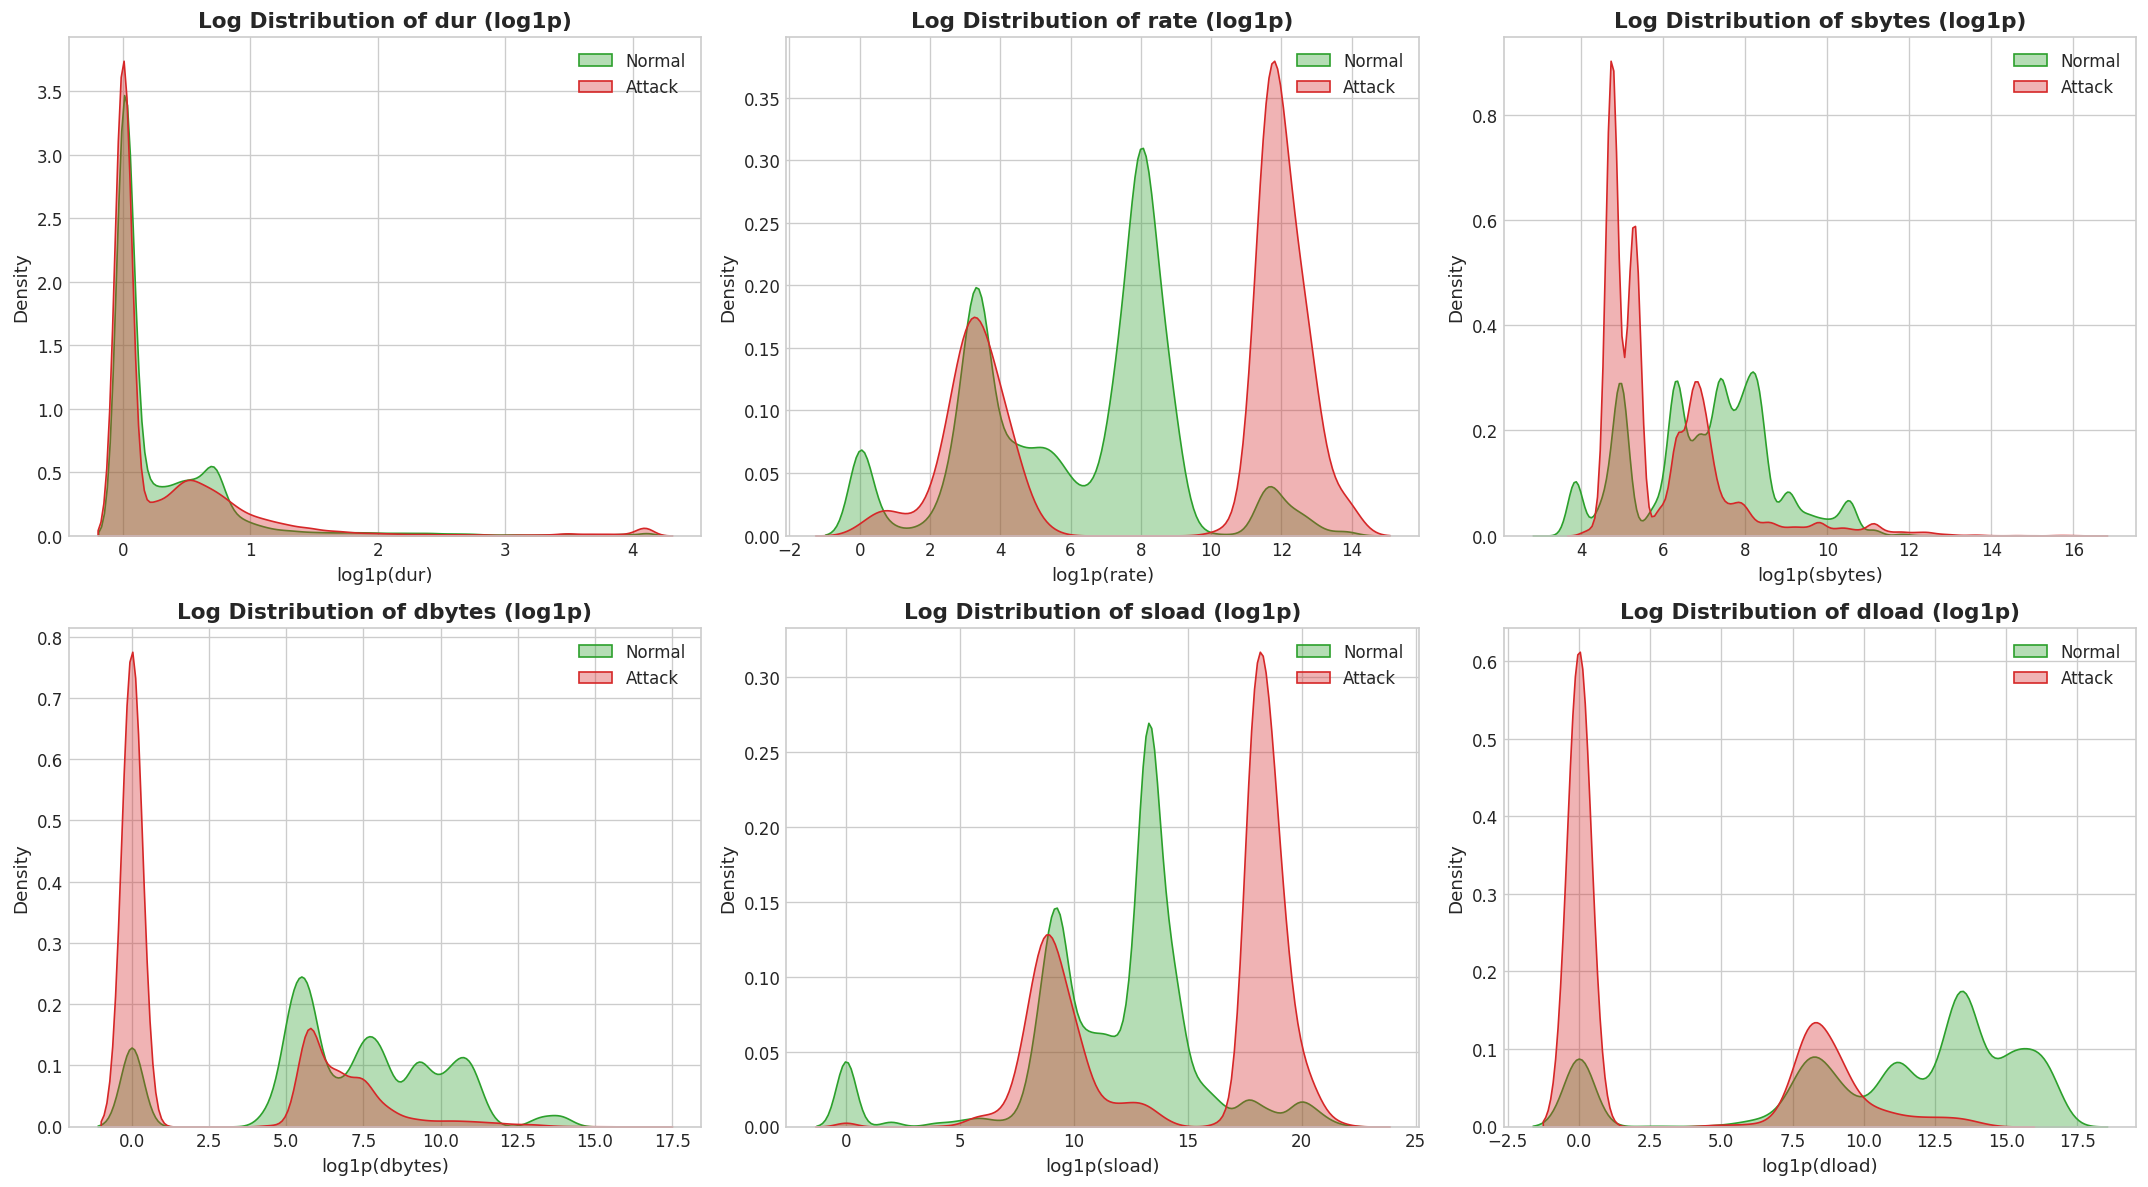

In [10]:
skewed_features = ['dur', 'rate', 'sbytes', 'dbytes', 'sload', 'dload']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(skewed_features):
    log_data_normal = np.log1p(df[df['label'] == 0][col])
    log_data_attack = np.log1p(df[df['label'] == 1][col])
    
    sns.kdeplot(log_data_normal, ax=axes[i], label='Normal', color='#2ca02c', fill=True, alpha=0.35)
    sns.kdeplot(log_data_attack, ax=axes[i], label='Attack', color='#d62728', fill=True, alpha=0.35)
    axes[i].set_title(f'Log Distribution of {col} (log1p)', fontweight='bold')
    axes[i].set_xlabel(f'log1p({col})')
    axes[i].legend(loc='upper right')

plt.tight_layout()
plt.show()


### Discriminative Analysis: Time-to-Live (TTL) and TCP Window Sizes
TTL features (`sttl`, `dttl`) and TCP window sizes (`swin`, `dwin`) are renowned in network security as strong discriminators for anomalous behavior and OS/stack fingerprinting.

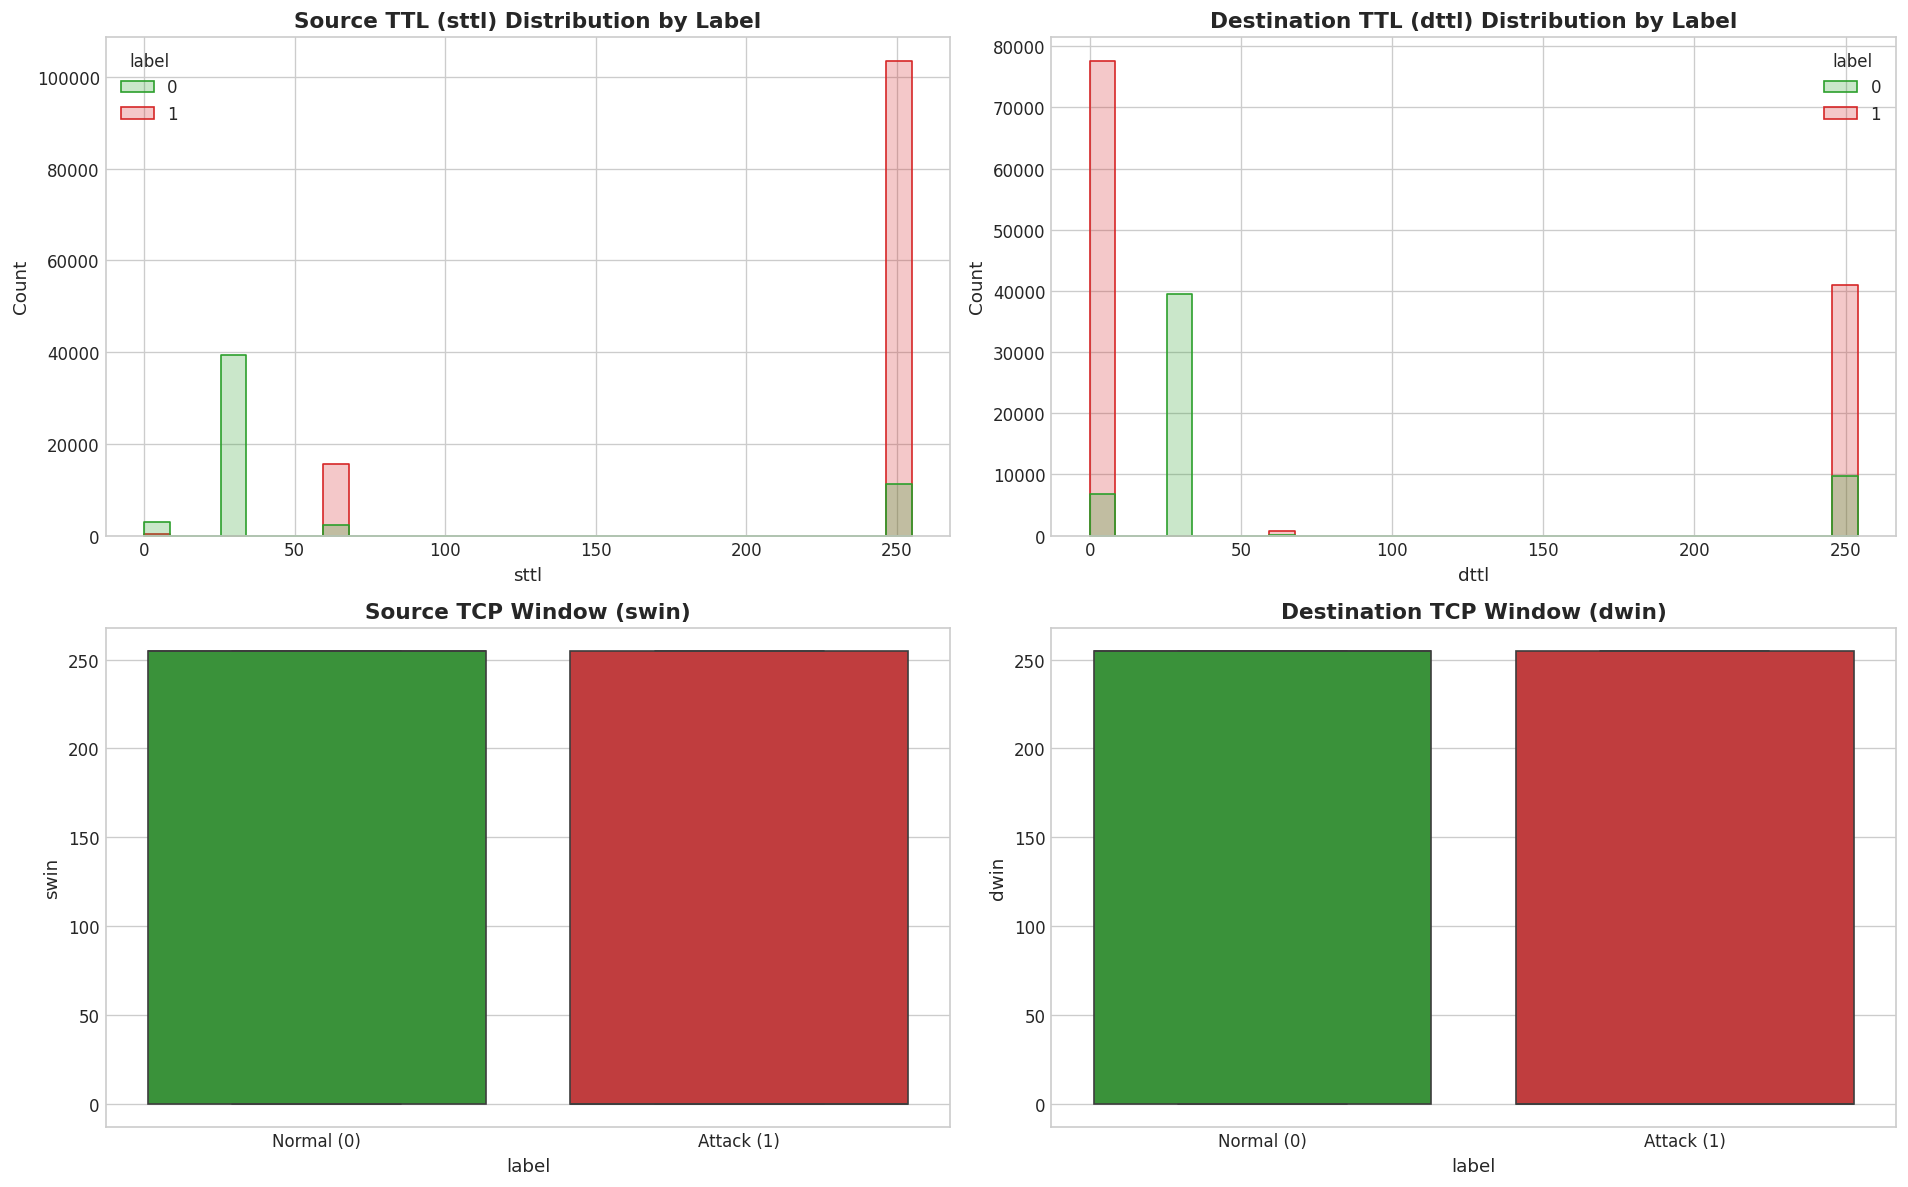

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.histplot(data=df, x='sttl', hue='label', bins=30, ax=axes[0, 0], palette=['#2ca02c', '#d62728'], kde=False, element='step')
axes[0, 0].set_title('Source TTL (sttl) Distribution by Label', fontweight='bold')

sns.histplot(data=df, x='dttl', hue='label', bins=30, ax=axes[0, 1], palette=['#2ca02c', '#d62728'], kde=False, element='step')
axes[0, 1].set_title('Destination TTL (dttl) Distribution by Label', fontweight='bold')

sns.boxplot(data=df, x='label', y='swin', ax=axes[1, 0], palette=['#2ca02c', '#d62728'])
axes[1, 0].set_xticklabels(['Normal (0)', 'Attack (1)'])
axes[1, 0].set_title('Source TCP Window (swin)', fontweight='bold')

sns.boxplot(data=df, x='label', y='dwin', ax=axes[1, 1], palette=['#2ca02c', '#d62728'])
axes[1, 1].set_xticklabels(['Normal (0)', 'Attack (1)'])
axes[1, 1].set_title('Destination TCP Window (dwin)', fontweight='bold')

plt.tight_layout()
plt.show()


## 6. Connection Count Features (`ct_*`) Analysis
The dataset contains numerous connection frequency attributes prefixed with `ct_` (e.g. connections to the same destination IP or port in a time window). These are critical for detecting DoS, port scans, and brute-force reconnaissance attacks.

Connection Count Features (10 features): ['ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst']


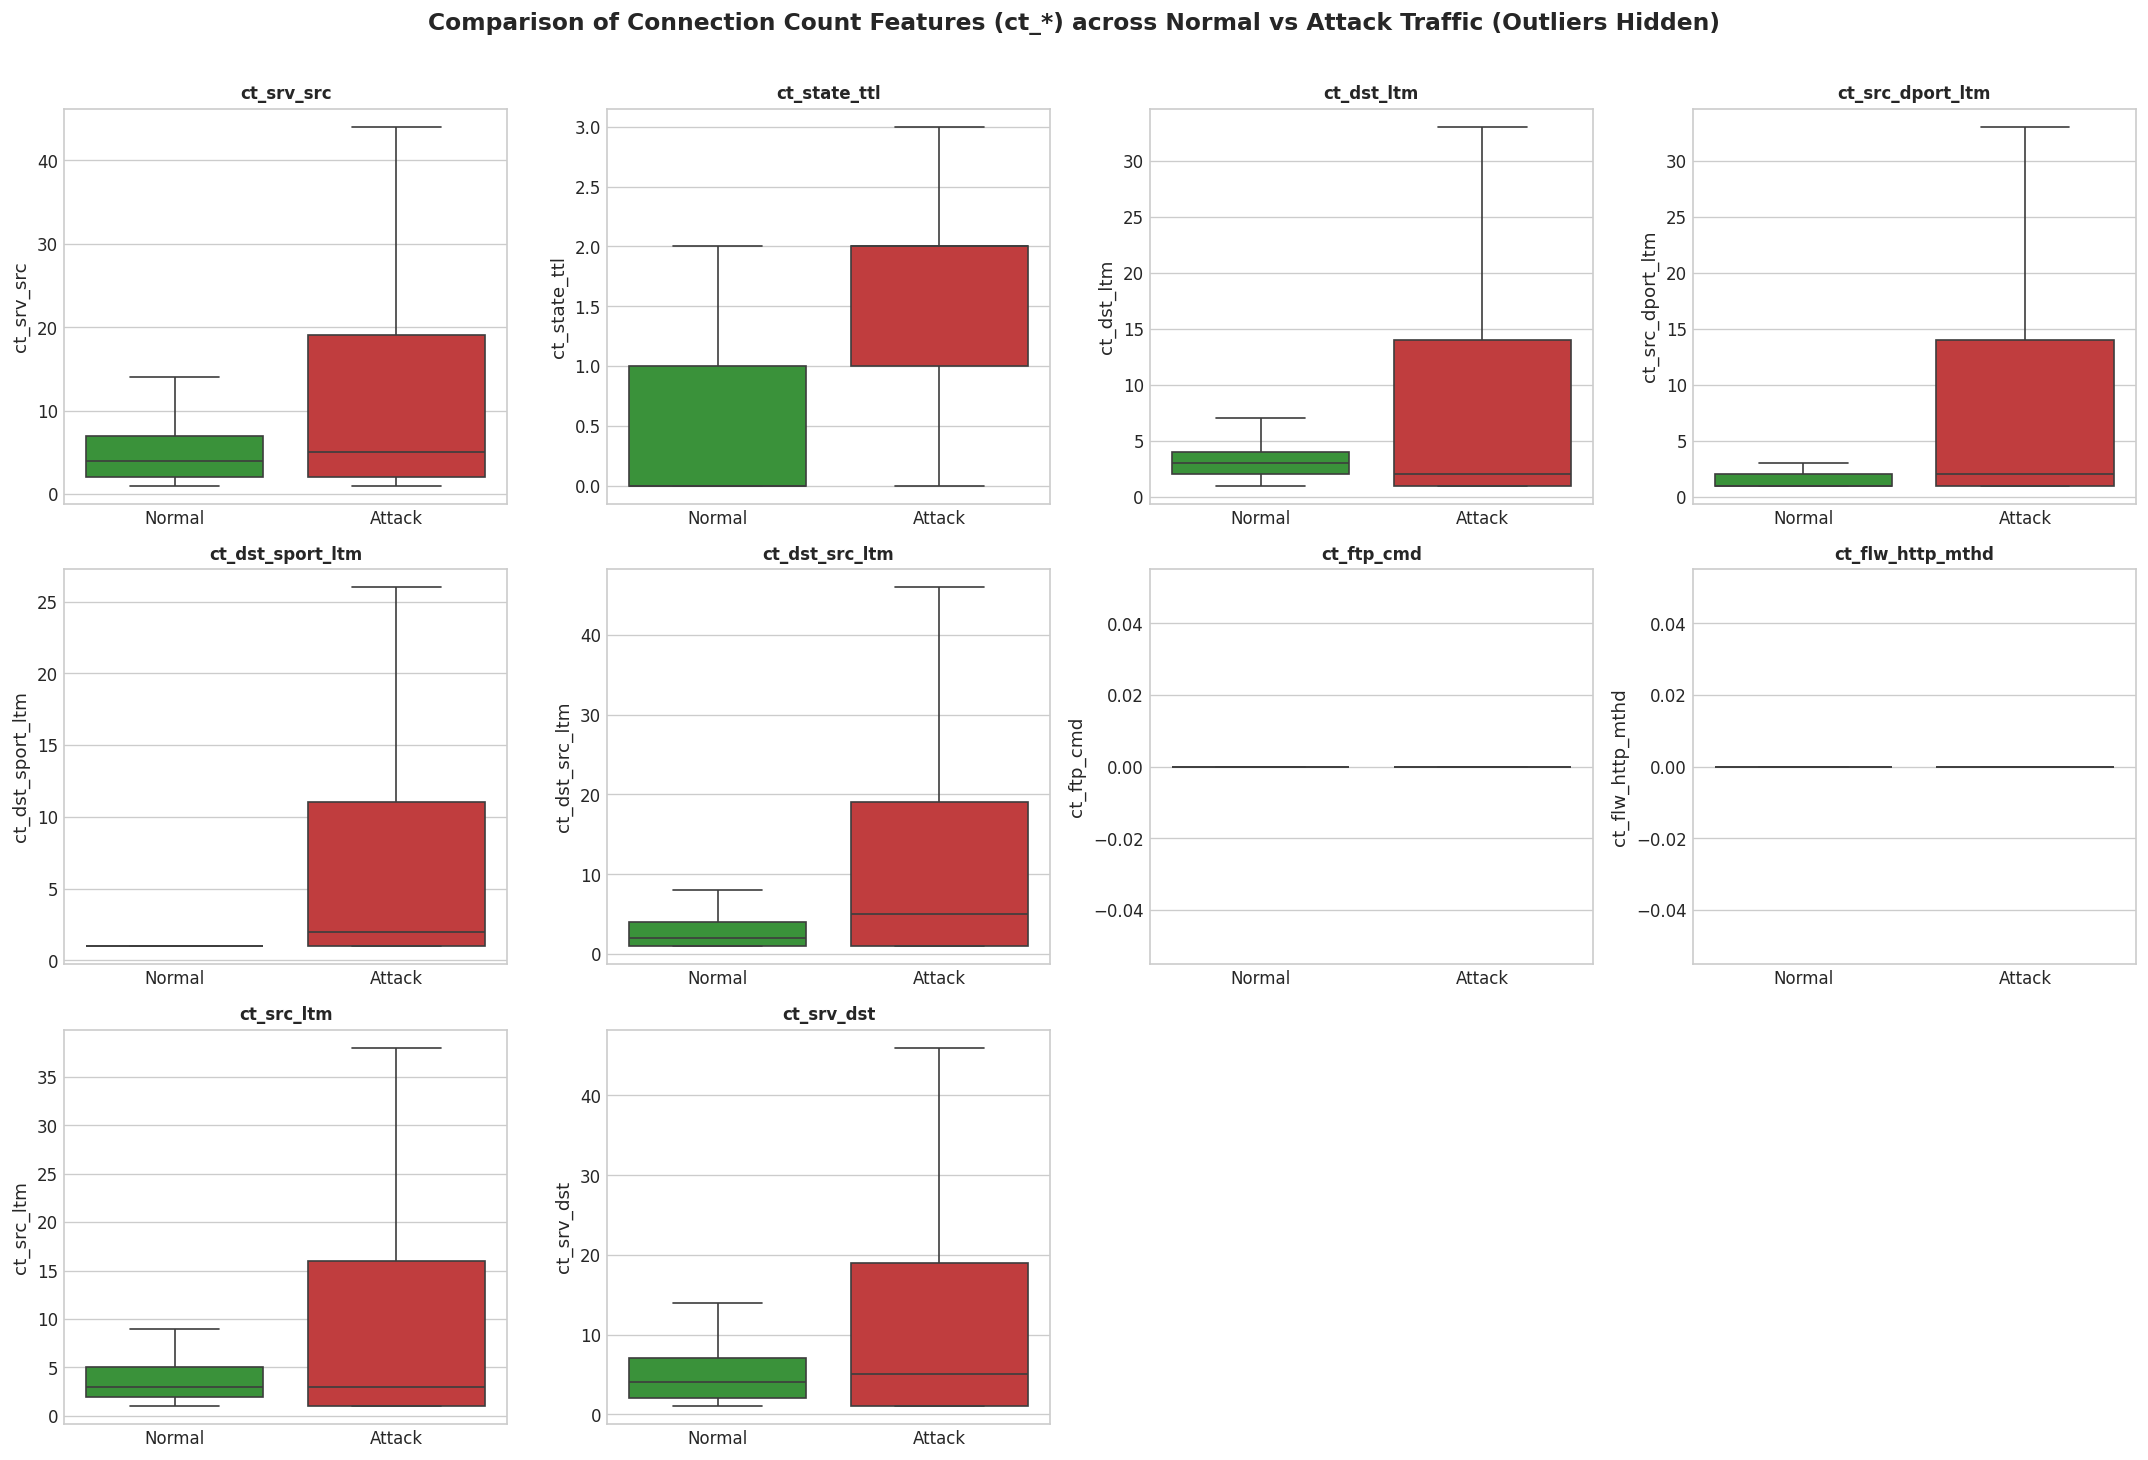

In [12]:
ct_cols = [c for c in df.columns if c.startswith('ct_')]
print(f"Connection Count Features ({len(ct_cols)} features): {ct_cols}")

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(ct_cols):
    sns.boxplot(data=df, x='label', y=col, ax=axes[i], palette=['#2ca02c', '#d62728'], showfliers=False)
    axes[i].set_title(col, fontweight='bold', fontsize=10)
    axes[i].set_xticklabels(['Normal', 'Attack'])
    axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Comparison of Connection Count Features (ct_*) across Normal vs Attack Traffic (Outliers Hidden)", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


## 7. Correlation & Multicollinearity Analysis
Evaluating pairwise correlations among features reveals redundant predictors and potential multicollinearity.

In [13]:
corr_matrix = df[num_cols + ['label']].corr()

corr_pairs = corr_matrix.abs().unstack()
corr_pairs = corr_pairs.sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 1.0]

seen = set()
redundant_pairs = []
for idx, val in corr_pairs.items():
    pair = tuple(sorted(idx))
    if pair not in seen and val > 0.85:
        seen.add(pair)
        redundant_pairs.append((pair[0], pair[1], val, corr_matrix.loc[pair[0], pair[1]]))

redundant_df = pd.DataFrame(redundant_pairs, columns=['Feature 1', 'Feature 2', 'Abs Correlation', 'Correlation'])
print(f"Highly Collinear Feature Pairs (|r| > 0.85): {len(redundant_df)} pairs")
display(redundant_df)


Highly Collinear Feature Pairs (|r| > 0.85): 23 pairs


,Feature 1,Feature 2,Abs Correlation,Correlation
0,dbytes,dloss,0.9965,0.9965
1,sbytes,sloss,0.9961,0.9961
2,dwin,swin,0.9901,0.9901
3,ct_srv_dst,ct_srv_src,0.9803,0.9803
4,dloss,dpkts,0.9786,0.9786
5,ct_dst_src_ltm,ct_srv_dst,0.9724,0.9724
6,dbytes,dpkts,0.9719,0.9719
7,sloss,spkts,0.9711,0.9711
8,ct_dst_src_ltm,ct_srv_src,0.9671,0.9671
9,sbytes,spkts,0.9638,0.9638


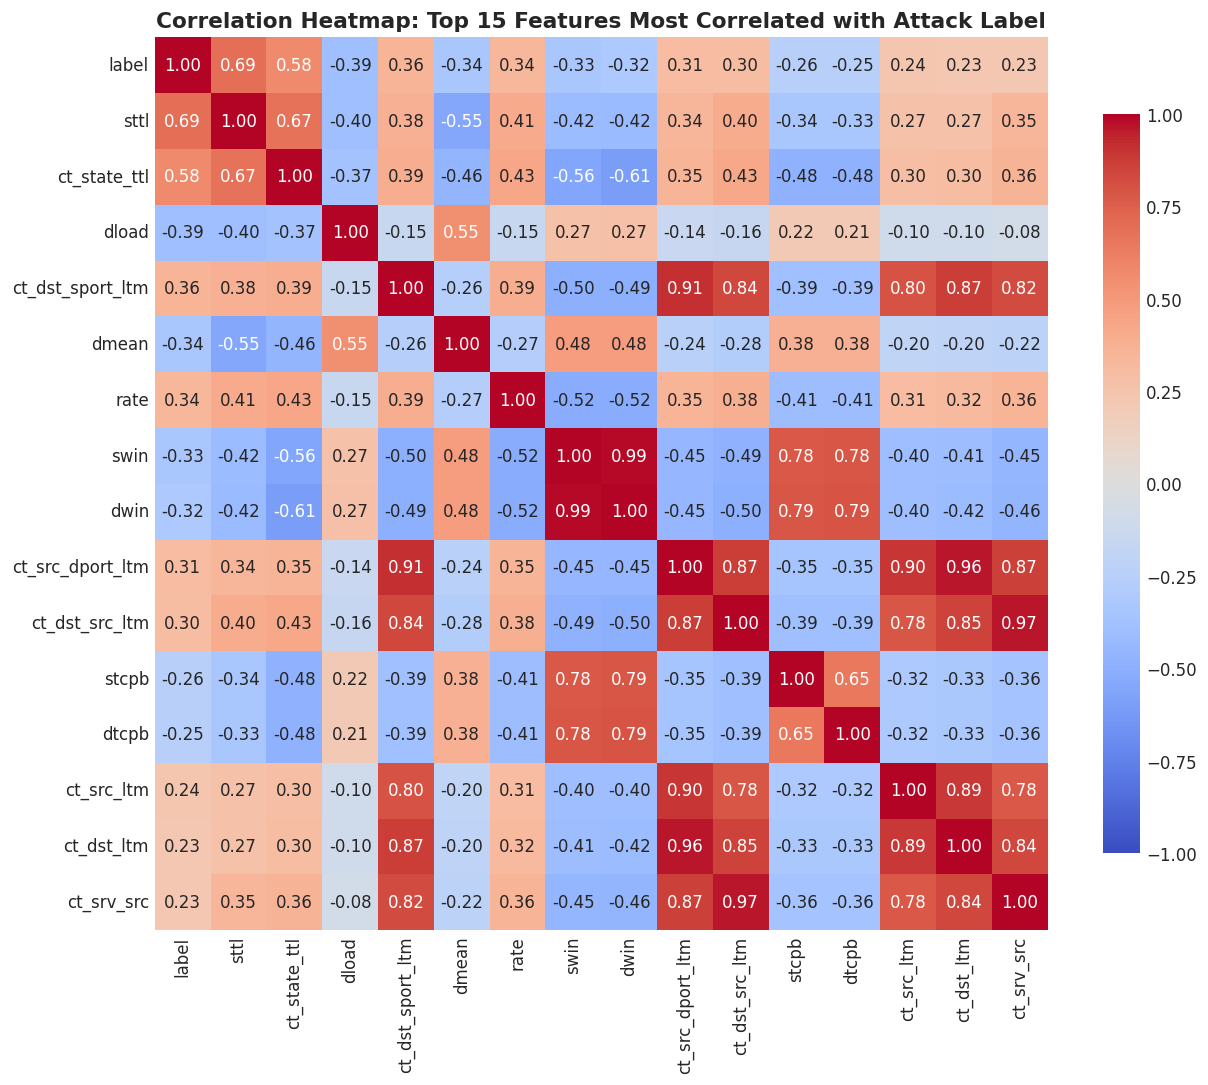

In [14]:
top_corr_with_target = corr_matrix['label'].abs().sort_values(ascending=False).head(16).index
plt.figure(figsize=(12, 10))
sns.heatmap(df[top_corr_with_target].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, cbar_kws={'shrink': .8})
plt.title('Correlation Heatmap: Top 15 Features Most Correlated with Attack Label', fontweight='bold', fontsize=13)
plt.show()


## 8. Feature Importance Screening via Random Forest
To complement linear correlation, let's train a fast non-linear tree-based ensemble (Random Forest) to evaluate multi-feature interactions and rank feature importances.

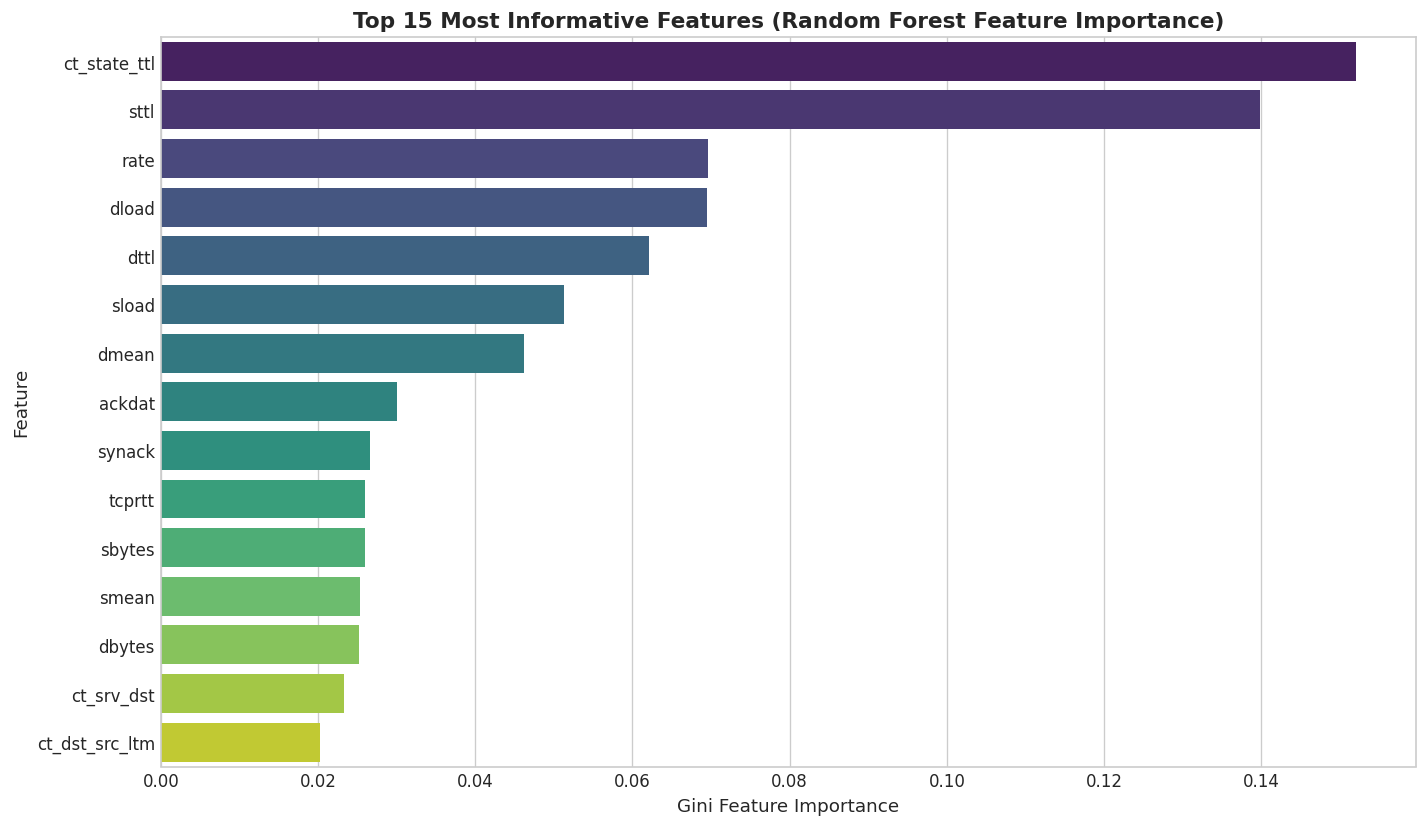

In [15]:
sample_df = df.sample(n=min(35000, len(df)), random_state=42).copy()

X_sample = sample_df.drop(columns=['id', 'attack_cat', 'label'])
for col in X_sample.select_dtypes(include=['object']).columns:
    X_sample[col] = LabelEncoder().fit_transform(X_sample[col].astype(str))

y_sample = sample_df['label']

rf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X_sample, y_sample)

importances = pd.Series(rf.feature_importances_, index=X_sample.columns).sort_values(ascending=False)

plt.figure(figsize=(12, 7))
sns.barplot(x=importances.head(15).values, y=importances.head(15).index, palette='viridis')
plt.title('Top 15 Most Informative Features (Random Forest Feature Importance)', fontweight='bold')
plt.xlabel('Gini Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


## 9. Key Findings & EDA Summary

### Analytical Summary:
1. **Target Distribution**:
   - The training set contains **119,341 (68.06%) Attack** instances and **56,000 (31.94%) Normal** instances.
   - Attack categories are heavily concentrated in `Generic` (40,000), `Exploits` (33,393), and `Fuzzers` (18,184).
   - Rare attacks like `Worms` (130 instances), `Shellcode` (1,133), and `Backdoor` (1,746) exhibit extreme scarcity, requiring stratified validation and resampling/cost-sensitive approaches.
2. **Missing & Placeholder Values**:
   - No `NaN` values exist in the dataset.
   - The `service` column has placeholder `'-'` in ~53.7% of rows (unspecified application-layer service).
3. **Distribution & Extreme Skewness**:
   - Network rate and volume features (`dur`, `sbytes`, `dbytes`, `sload`, `dload`, `rate`, `sjit`, `djit`) span several orders of magnitude with extreme right-skew.
   - Applying `log1p` or robust quantile scaling is essential before passing these features to linear models, distance-based algorithms, or neural networks.
4. **Strongest Discriminative Features**:
   - `sttl` (Source TTL) and `ct_state_ttl` exhibit strong separation between normal traffic and attacks due to synthetic packet craft tools having fixed default TTLs.
   - Connection count metrics (`ct_srv_src`, `ct_dst_src_ltm`, etc.) show elevated values during attack traffic (e.g. DoS and Reconnaissance).
5. **Collinearity & Feature Redundancy**:
   - 23 feature pairs have Pearson $|r| > 0.85$ (e.g. `(spkts, sloss)`, `(dpkts, dloss)`, `(sbytes, sloss)`).


---
# 10. Data Cleaning & Transformation Pipeline

Based on the EDA findings and the standard NetFlow common feature specification defined in `datasets/feature_dataset.xlsx` (`common_features` sheet), we now match the legacy UNSW-NB15 features with the standard common feature set based on their semantic descriptions.

### Feature Matching Table (based on descriptions):

| Common Feature Name (`feature_dataset.xlsx`) | Common Feature Description | Legacy UNSW-NB15 Feature | Description & Transformation Logic |
| :--- | :--- | :--- | :--- |
| **`FLOW DURATION MILLISECONDS`** | Flow duration in milliseconds | `dur` | Record total duration (in seconds, converted via `dur * 1000`) |
| **`IN BYTES`** | Incoming number of bytes | `sbytes` | Source to destination transaction bytes |
| **`OUT BYTES`** | Outgoing number of bytes | `dbytes` | Destination to source transaction bytes |
| **`IN PKTS`** | Incoming number of packets | `spkts` | Source to destination packet count |
| **`OUT PKTS`** | Outgoing number of packets | `dpkts` | Destination to source packet count |
| **`SRC TO DST SECOND BYTES`** | Src to dst Bytes/sec | `sload` | Source bits per second (converted via `sload / 8`) |
| **`SRC TO DST AVG THROUGHPUT`** | Src to dst average thpt (bps) | `sload` | Source bits per second (bps) |
| **`TCP WIN MAX IN`** | Max TCP Window (src->dst) | `swin` | Source TCP window advertisement value |
| **`TCP WIN MAX OUT`** | Max TCP Window (dst->src) | `dwin` | Destination TCP window advertisement value |
| **`Attack_Type`** *(Target)* | Attack category name | `attack_cat` | Normalized attack category (`Normal`, `Generic`, `Exploits`, etc.) |
| **`Attack_Indicator`** *(Target)* | Binary attack indicator | `label` | 0 for Normal, 1 for Attack |
| **`Dataset`** *(Provenance)* | Source dataset origin | - | Constant `'UNSW-NB15'` |

> **Note on Dropped Features:** As instructed, all legacy features not matching the common feature descriptions (e.g. `id`, `rate`, `stcpb`, `dtcpb`, `smean`, `dmean`, `trans_depth`, `response_body_len`, `ct_*`, `is_*`) are dropped, retaining only the matched common predictors and the attack type and attack indicator targets.


In [ ]:
def transform_unsw_dataset(data: pd.DataFrame) -> pd.DataFrame:
    """
    Transforms raw UNSW-NB15 dataset by matching legacy features to the standard
    common feature set (feature_dataset.xlsx) and dropping non-matched features.
    """
    df_out = pd.DataFrame()
    
    # 1. Match and transform flow predictors
    df_out['FLOW DURATION MILLISECONDS'] = (data['dur'] * 1000.0).astype(np.float32)
    df_out['IN BYTES'] = data['sbytes'].astype(np.int64)
    df_out['OUT BYTES'] = data['dbytes'].astype(np.int64)
    df_out['IN PKTS'] = data['spkts'].astype(np.int64)
    df_out['OUT PKTS'] = data['dpkts'].astype(np.int64)
    df_out['SRC TO DST SECOND BYTES'] = (data['sload'] / 8.0).astype(np.float32)
    df_out['SRC TO DST AVG THROUGHPUT'] = data['sload'].astype(np.float32)
    df_out['TCP WIN MAX IN'] = data['swin'].astype(np.int64)
    df_out['TCP WIN MAX OUT'] = data['dwin'].astype(np.int64)
    
    # 2. Attack category harmonization & target assignment
    attack_cat = data['attack_cat'].fillna('Normal').astype(str).str.strip()
    attack_cat = attack_cat.replace({
        'Backdoors': 'Backdoor',
        'Fuzzers ': 'Fuzzers',
        'Reconnaissance ': 'Reconnaissance',
        'Shellcode ': 'Shellcode',
        'normal': 'Normal'
    })
    df_out['Attack_Type'] = attack_cat
    df_out['Attack_Indicator'] = data['label'].astype(np.int32)
    df_out['Dataset'] = 'UNSW-NB15'
    
    return df_out

# Apply transformation to the loaded training set
print("Applying feature transformation to UNSW-NB15 training dataset...")
df_unsw_train_derived = transform_unsw_dataset(df)
print(f"Transformed Training Set Shape: {df_unsw_train_derived.shape[0]:,} rows x {df_unsw_train_derived.shape[1]} columns")
display(df_unsw_train_derived.head())


In [ ]:
print("--- Quality Verification for Transformed UNSW-NB15 ---")
print("Null counts per column:")
print(df_unsw_train_derived.isnull().sum())
print("\nAttack Indicator breakdown:")
print(df_unsw_train_derived['Attack_Indicator'].value_counts())
print("\nAttack Type breakdown:")
print(df_unsw_train_derived['Attack_Type'].value_counts())


### Processing Testing Set & Exporting Derived UNSW-NB15 Dataset

We load `UNSW_NB15_testing-set.csv`, apply the exact same transformation function, and combine both partitions into the complete derived UNSW-NB15 dataset ($N = 257,673$). We then export `UNSW_NB15_derived.csv`.


In [ ]:
test_candidates = [
    Path('../../datasets/UNSW-NB15 dataset/CSV Files/Training and Testing Sets/UNSW_NB15_testing-set.csv'),
    Path('datasets/UNSW-NB15 dataset/CSV Files/Training and Testing Sets/UNSW_NB15_testing-set.csv'),
    Path(r'd:/Swinburne Courses/Project A/datasets/UNSW-NB15 dataset/CSV Files/Training and Testing Sets/UNSW_NB15_testing-set.csv')
]

test_path = next((p for p in test_candidates if p.exists()), None)
if test_path is None:
    raise FileNotFoundError("Could not locate UNSW_NB15_testing-set.csv")

print(f"Loading raw testing dataset from: {test_path.resolve()}")
df_test_raw = pd.read_csv(test_path)
df_unsw_test_derived = transform_unsw_dataset(df_test_raw)

# Combine training and testing into complete derived UNSW dataset
df_unsw_master = pd.concat([df_unsw_train_derived, df_unsw_test_derived], ignore_index=True)
print(f"Combined UNSW-NB15 Derived Dataset: {df_unsw_master.shape[0]:,} rows x {df_unsw_master.shape[1]} columns")

# Export derived dataset
datasets_root = Path(r'd:/Swinburne Courses/Project A/datasets')
unsw_derived_path = datasets_root / 'UNSW_NB15_derived.csv'
df_unsw_master.to_csv(unsw_derived_path, index=False)
print(f"-> Exported derived UNSW dataset to: {unsw_derived_path.resolve()}")


### 11. Unified Multi-Dataset Export (`uniform_IDS.csv`)

Per project requirements, **no pre-splitting is applied**. Instead, the derived UNSW-NB15 dataset and the derived CIC-IDS-2017 dataset are combined into a single unified CSV file named `uniform_IDS.csv`.

This file provides an aligned, uniform flow feature space across both benchmark environments without data loss or pre-partition bias.


In [ ]:
cic_derived_path = datasets_root / 'CIC_IDS_2017_derived.csv'
uniform_export_path = datasets_root / 'uniform_IDS.csv'

if cic_derived_path.exists():
    print(f"Loading derived CIC-IDS-2017 from: {cic_derived_path.resolve()}...")
    df_cic_derived = pd.read_csv(cic_derived_path)
    print(f"CIC-IDS-2017 shape: {df_cic_derived.shape[0]:,} rows x {df_cic_derived.shape[1]} columns")
    
    print("Combining UNSW-NB15 and CIC-IDS-2017 into uniform_IDS.csv...")
    df_uniform = pd.concat([df_unsw_master, df_cic_derived], ignore_index=True)
    df_uniform.to_csv(uniform_export_path, index=False)
    print(f"-> Saved unified dataset to: {uniform_export_path.resolve()}")
    print(f"   Total shape: {df_uniform.shape[0]:,} rows x {df_uniform.shape[1]} columns")
    print("\nDataset Breakdown:")
    print(df_uniform['Dataset'].value_counts())
else:
    print(f"CIC-IDS-2017 derived file not yet found at {cic_derived_path}. Please execute cic2017.ipynb to generate it.")
